# 数值积分 ― integrate 模块

## 本章要学什么

`integrate` 模块里有计算定积分的函数，也有解常微分方程的函数，这一章用例子确认下面的内容。

- 用 `quad()` 数值计算定积分
- 二重积分与三重积分(`dblquad()`、`tplquad()`)
- 解常微分方程(`odeint()`、`solve_ivp()`)
- 质量-弹簧-阻尼系统与 PID 控制的仿真
- 用质点和弹簧模拟悬链线
- 解边界值问题(`solve_bvp()`)

In [1]:
from matplotlib import pyplot as plt

import helper.matplotlib
import numpy as np
from scipy import integrate, optimize
from scipy.integrate import odeint

## 计算定积分

数值积分是用数值方法求定积分，也可以用来计算图形的面积。作为例子，这里求半径为 1 的半圆的面积，它应当是 $\pi/2$。单位半圆的曲线是 $y=\sqrt{1-x^2}$，可以用下面的函数表示。

In [2]:
def half_circle(x):
    return (1 - x**2) ** 0.5

最简单的数值积分是把面积切成很多细长的长方形再相加：把 x 轴上 -1 到 1 之间分成 10000 等份，再把这些长方形的面积加起来。

In [3]:
N = 10000
x = np.linspace(-1, 1, N)
dx = x[1] - x[0]
y = half_circle(x)
2 * dx * np.sum(y)   # 半圆面积的 2 倍(圆面积)

np.float64(3.1415893269307373)

用 NumPy 的 `trapezoid()` 可以算出连接各点的折线与 x 轴之间的面积，精度比用长方形近似更高。

In [4]:
np.trapezoid(y, x) * 2

np.float64(3.141589326931597)

用 `integrate.quad()` 能得到更准确的值，它返回(积分值, 误差估计值)这样的元组。

In [5]:
area_half, err = integrate.quad(half_circle, -1, 1)
area_half * 2

3.1415926535897967

## 多重积分

二重积分也可以调用两次 `quad()` 来算，但用 `integrate.dblquad()` 更方便，三重积分则用 `tplquad()`。

作为例子，这里计算单位半球的体积。半球面上的点 $(x,y,z)$ 满足 $x^2 + y^2 + z^2 = 1$，所以由 x、y 就能求出 z，如下面的函数。

In [6]:
def half_sphere(x, y):
    return (1 - x**2 - y**2) ** 0.5

xy 平面与这个半球的交线是单位圆，因此 x 从 -1 积到 1，y 从 $-\sqrt{1-x^2}$ 积到 $\sqrt{1-x^2}$，写成式子就是下面这样。

$$\int_{-1}^{1}{\int_{-\sqrt{1-x^2}}^{\sqrt{1-x^2}}{\sqrt{1-x^2-y^2} dy} dx}$$

下面的程序用 `dblquad()` 计算这个体积。

In [7]:
volume, error = integrate.dblquad(
    half_sphere, -1, 1, lambda x: -half_circle(x), lambda x: half_circle(x)
)

print(volume, error, np.pi * 4 / 3 / 2)   # 球体积的一半

2.0943951023931984 1.0002354500215915e-09 2.0943951023931953


`dblquad()` 的参数是 `dblquad(func2d, a, b, gfun, hfun)`：`func2d` 是要积分的函数、接受两个参数，`a` 与 `b` 是第 1 个参数 x 的区间，`gfun` 与 `hfun` 是第 2 个参数 y 的区间。`gfun` 与 `hfun` 都是函数，由 x 算出 y 的区间，这样一来就能在 xy 平面上的任意区域上积分。

下图是二重积分的思路：x 的区间是 -1 到 1，对 x 轴上的某点 x0 沿 y 方向积分，得到的就是图中深色截面的面积，而 y 的区间就是图中虚线所示的范围。

![半球二重积分示意图](images/scipy_integrate.png)

## 解常微分方程

`integrate` 模块里还有解常微分方程(ODE)的 `odeint()`，这里以洛伦兹吸引子的轨迹为例，方程如下。

$$\frac{dx}{dt} = \sigma \cdot (y - x), \ \ 
\frac{dy}{dt} = x \cdot (\rho - z) - y, \ \ 
\frac{dz}{dt} = xy - \beta z$$ 

这个方程给出三维空间各个点上的速度：从某一点出发沿速度方向积分，就能知道点在这个空间里会怎样运动。$\sigma$、$\rho$、$\beta$ 是常数，取值不同，轨迹 $x(t)$、$y(t)$、$z(t)$ 也不同；某些取值下轨迹会变成混沌，初始值上一点点差别就会被放大。

下面的程序计算这条轨迹：❶ `lorenz()` 返回某个点上各方向的微分值。❷❸ 把初始值稍作改动，调用两次 `odeint()`。

传给 `odeint()` 的参数如下。

1. `lorenz`：计算某位置速度的函数
2. `(0.0, 1.0, 0.0)`：各变量的初始值
3. `t`：时间数组，要计算各个时刻的状态
4. `args`：原样传给 `lorenz()` 的常数
5. `tfirst`：为 `True` 时，`lorenz()` 的第 1 个参数是时刻 `t`、第 2 个参数是状态

```{seealso}
http://bzhang.lamost.org/website/archives/lorenz_attactor

洛伦兹吸引子的详细说明
```

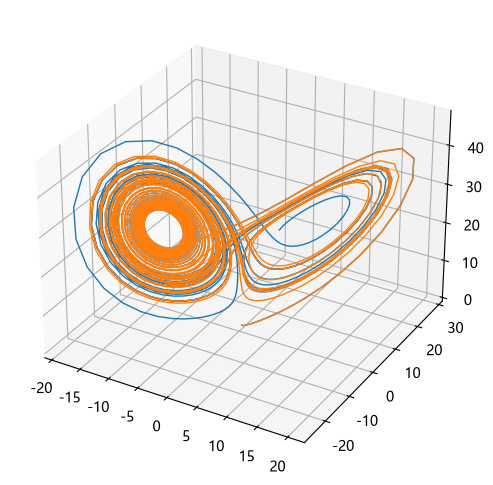

In [8]:
from scipy.integrate import odeint


def lorenz(t, w, p, r, b):  #❶
    """返回位置 w 处的 dx/dt, dy/dt, dz/dt。"""
    x, y, z = w.tolist()
    return p * (y - x), x * (r - z) - y, x * y - b * z


t = np.arange(0, 30, 0.02)
track_a = odeint(lorenz, (0.0, 1.00, 0.0), t, args=(10.0, 28.0, 3.0), tfirst=True)  #❷
track_b = odeint(lorenz, (0.0, 1.01, 0.0), t, args=(10.0, 28.0, 3.0), tfirst=True)  #❸

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(1, 1, 1, projection="3d")
ax.plot(track_a[:, 0], track_a[:, 1], track_a[:, 2], lw=1)
ax.plot(track_b[:, 0], track_b[:, 1], track_b[:, 2], lw=1)
plt.show()

从图上可以看出，初始值只差 0.01，两条轨迹就完全不同。

`odeint()` 要求自己指定记录状态的时刻，而新的 `solve_ivp()` 让积分算法自己去决定需要的时刻。下面的程序用 `solve_ivp()` 解同一个系统。

前三个参数分别是返回微分值的函数、积分区间与初始状态，`method` 是积分算法，`RK45` 就是经典的龙格-库塔法。返回值是 `OdeResult`，其中 `t` 与 `y` 是时刻和状态；把 `dense_output=True` 设上，`sol` 属性里就会放入用于插值的对象，可以算出任意时刻的状态。

In [9]:
from scipy.integrate import solve_ivp

res = solve_ivp(
    lorenz, (0, 30), (0, 1, 0), args=(10, 28, 3), method="RK45", dense_output=True
)
print("segments = {}, t length={}".format(res.sol.n_segments, len(res.t)))

segments = 348, t length=349


调用 `OdeSolution` 对象就能算出任意时刻的状态。这里把区间分成 20000 个点做插值，再与积分的点画在一起：光滑的曲线是插值结果，圆点是 `solve_ivp()` 算出的状态。

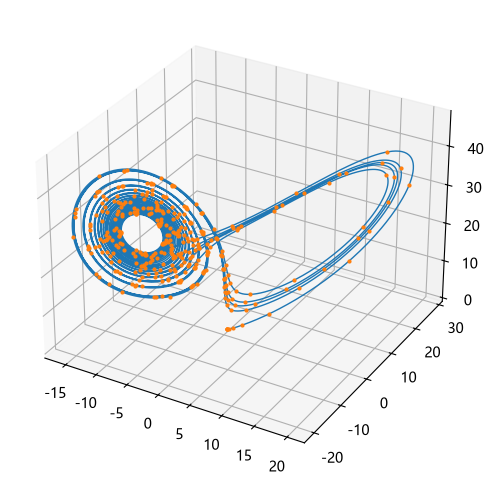

In [10]:
t = np.linspace(0, 30, 20000)
x, y, z = res.sol(t)

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(1, 1, 1, projection="3d")
ax.plot(x, y, z, lw=1)
x2, y2, z2 = res.y
ax.plot(x2, y2, z2, "o", ms=2)
plt.show()

## 质量-弹簧-阻尼系统

接下来仿真下图那样的质量-弹簧-阻尼系统，并用 PID 控制器控制它的位置，系统的方程如下。

$$m \ddot{x} + b \dot{x} + k x = F$$

其中 $x$ 是位移、$\dot{x}$ 是速度、$\ddot{x}$ 是加速度，$m$ 是质量、$b$ 是阻尼系数、$k$ 是弹簧系数、$F$ 是外加的力。

这是二阶微分方程，要用 `odeint()` 求解就得先化成一阶的联立方程。

$$
\begin{align*}
\dot{x} &= u \\ 
\dot{u} &= (F - k x - b u)/m
\end{align*}
$$

其中 $x$ 是位移、$u$ 是速度，这两个量就是系统的状态。

![质量-弹簧-阻尼系统](images/mass_spring_damper.png)

下面的 `MassSpringDamper` 类持有参数 `m`、`k`、`b` 与力 `force`，用 `diff()` 计算位移与速度的微分。

In [11]:
class MassSpringDamper:
    def __init__(self, m, k, b, force=0):
        self.m, self.k, self.b = m, k, b
        self.force = force

    def diff(self, t, status):
        """返回状态 (x, u) 的微分。"""
        x, u = status
        dx = u
        du = (self.force - self.k * x - self.b * u) / self.m
        return [dx, du]

用 `odeint()` 解这个系统：初始位移与速度都是 0，力始终为 1，结果如下图所示，大约 2 秒之后位移稳定在 0.05。

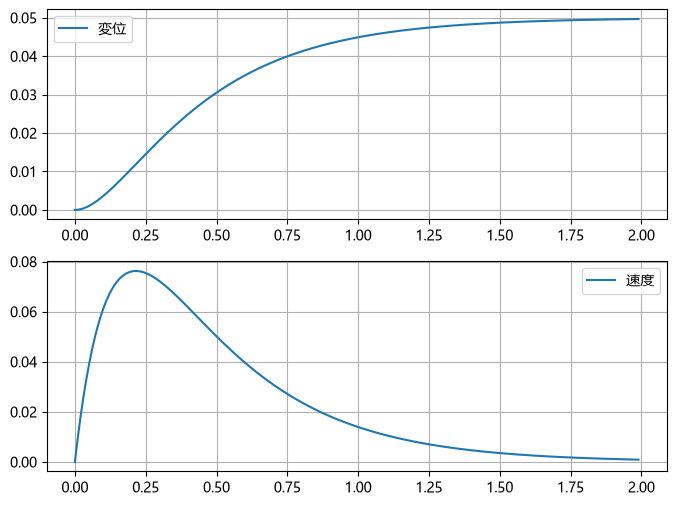

In [12]:
m, k, b, force = 1.0, 20.0, 10.0, 1.0
open_system = MassSpringDamper(m, k, b, force)
init_status = 0.0, 0.0
t = np.arange(0, 2, 0.01)
result = odeint(open_system.diff, init_status, t, tfirst=True)

fig, axes = plt.subplots(2, 1, figsize=(8, 6))
axes[0].plot(t, result[:, 0], label="変位")
axes[1].plot(t, result[:, 1], label="速度")
for ax in axes:
    ax.legend()
    ax.grid()
plt.show()

如果调整外加的力 $F$，就能更快地停在位移 1.0 上，为此要用 PID 控制器，下图是 PID 控制的结构。

![PID 控制系统](images/PID-system.svg)

图中 Setpoint 是目标值，在这个例子里就是目标位移；Process 是被控对象，Output 是它的输出、也就是实际的位移；两者之差 Error 则成为 PID 控制器的输入。PID 控制器由三部分组成。

* P：比例项，输出与误差成正比。
* I：积分项，输出与误差的积分成正比。
* D：微分项，输出与误差的微分成正比。

三项之和就是控制器的输出，在这个例子里就是加在质量上的力 $F$。

下面的 `PIDControl` 类持有 `kp`、`ki`、`kd` 与目标位移 `x_ref`：`control_force()` 计算控制力，而状态 `status` 由位移、速度、误差的积分这三者组成。控制力就是把误差、误差的积分、误差的微分分别乘上增益再相加，其中误差的微分等于速度乘 -1。

In [13]:
class PIDControl:
    def __init__(self, kp, ki, kd, x_ref):
        self.kp, self.ki, self.kd = kp, ki, kd
        self.x_ref = x_ref

    def control_force(self, status):
        x, u, eint = status
        self.err = self.x_ref - x
        force = self.kp * self.err + self.ki * eint + self.kd * (-u)
        return force

下面的 `System` 类把 `MassSpringDamper` 与 `PIDControl` 合在一起，用 `diff()` 返回位移、速度、误差积分的微分。

In [14]:
class System:
    def __init__(self, m, k, b, kp, ki, kd, x_ref):
        self.target = MassSpringDamper(m, k, b)
        self.pid = PIDControl(kp, ki, kd, x_ref)

    def diff(self, t, status):
        x, u, eint = status
        self.target.force = self.pid.control_force(status)
        dx, du = self.target.diff(t, [x, u])
        return dx, du, self.pid.err

用 `odeint()` 对带 PID 控制的系统做仿真：算出各时刻的状态之后，再把这个状态传给 `control_force()` 求出控制力。

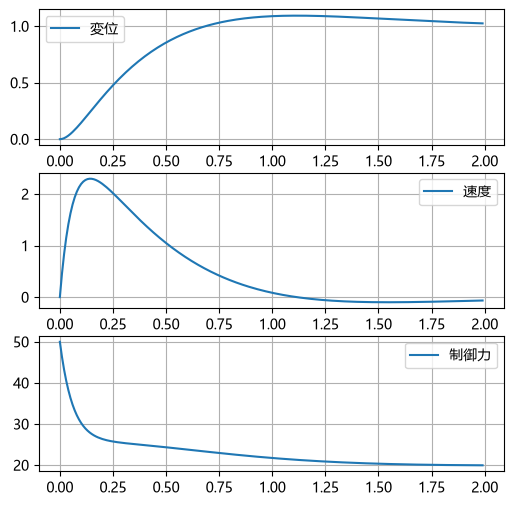

In [15]:
system = System(m=m, k=k, b=b, kp=50, ki=100, kd=10, x_ref=1)
init_status = 0.0, 0.0, 0.0
dt = 0.01
t = np.arange(0, 2, dt)
res_pid = odeint(system.diff, init_status, t, tfirst=True)

x, v, eint = res_pid.T
force = system.pid.control_force(res_pid.T)


def plot_result(t, x, v, force):
    fig, axes = plt.subplots(3, 1, figsize=(6, 6))
    for ax in axes:
        ax.grid(True)
    axes[0].plot(t, x, label="変位")
    axes[0].legend(loc="best")
    axes[1].plot(t, v, label="速度")
    axes[1].legend(loc="best")
    axes[2].plot(t, force, label="制御力")
    axes[2].legend(loc="best")
    plt.show()


plot_result(t, x, v, force)

把 PID 的三个参数调好，控制的效果就会改善。这里可以用上一章的 `optimize` 自动搜索参数，为此需要准备一个评价控制结果的函数。目标是尽可能快地停在位移 1.0 上，所以用最初 2 秒内误差的平方和作为评价，这个值越小说明控制得越好。

In [16]:
%%time


def pid_control_system(kp, ki, kd, dt, m=1.0, k=20.0, b=10.0, tend=2):
    """传入 PID 参数，返回位移、速度与控制力。"""
    system = System(m=m, k=k, b=b, kp=kp, ki=ki, kd=kd, x_ref=1)
    init_status = 0.0, 0.0, 0.0
    t = np.arange(0, tend, dt)
    res = odeint(system.diff, init_status, t, tfirst=True)
    force = system.pid.control_force(res.T)
    return t, res.T, force


def eval_func(k):
    kp, ki, kd = k
    t, (x, v, eint), force = pid_control_system(kp, ki, kd, 0.01)
    return np.sum((x - 1.0) ** 2)


kwargs = {"method": "L-BFGS-B", "bounds": [(10, 1000), (10, 1000), (1, 200)]}

opt_k = optimize.basinhopping(
    eval_func, (10, 10, 10), niter=10, minimizer_kwargs=kwargs
)
print(opt_k.x, opt_k.fun)

[382.61456316 106.92676064   9.16511212] 5.675583260220519
CPU times: total: 5.22 s
Wall time: 5.55 s


用找到的参数再仿真一次：开始控制后 0.5 秒，位移就基本稳定在 1.0。

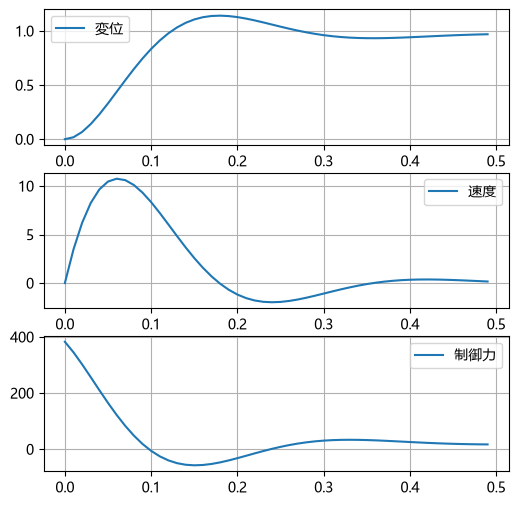

In [17]:
t, (x, v, eint), force = pid_control_system(*opt_k.x, dt=0.01, tend=0.5)
plot_result(t, x, v, force)

## 悬链线的仿真

用牛顿运动方程可以仿真悬链线：把悬链线想成一串用弹簧连接的质点，每个质点受到重力和左右两根弹簧的力，运动时还有与速度成正比的阻力。两端的质点固定、不计算受力，所以它们的加速度始终是 0。

每个质点在 x、y 方向各有速度与加速度，一共 4 个状态，N 个质点就有 4N 个状态。下面的 `diff_status()` 返回状态的微分，再用 `solve_ivp()` 积分；时间足够长之后，阻力会让各质点停在平衡位置上。

a= 0.337 length= 1.377 solve length= 1.410


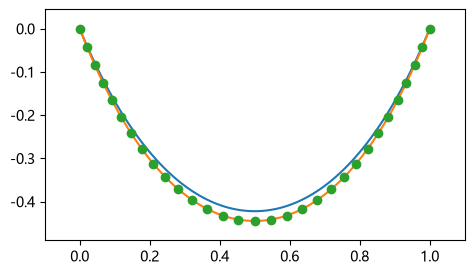

In [18]:
import math


def catenary(x, a):
    return a * np.cosh((x - 0.5) / a) - a * np.cosh((-0.5) / a)


def catenary_length(a):
    def fs(x):
        return (math.sinh((x - 0.5) / a) ** 2 + 1) ** 0.5

    return integrate.quad(fs, 0, 1)[0]


a = 0.35
length = catenary_length(a)
N = 31
dump = 0.2          # 減衰係数
k = 100.0           # 弹簧系数
l = length / (N - 1)  # 弹簧的自然长度
g = 0.01            # 重力加速度

x0 = np.linspace(0, 1, N)
y0 = np.zeros_like(x0)
vx0 = np.zeros_like(x0)
vy0 = np.zeros_like(x0)


def diff_status(t, status):
    """返回质点列状态 (x, y, vx, vy) 的微分。"""
    x, y, vx, vy = status.reshape(4, -1)
    dvx = np.zeros_like(x)
    dvy = np.zeros_like(x)
    dx = vx
    dy = vy

    s = np.s_[1:-1]     # 两端固定，只计算内侧

    len_left = np.sqrt((x[s] - x[:-2]) ** 2 + (y[s] - y[:-2]) ** 2)
    len_right = np.sqrt((x[s] - x[2:]) ** 2 + (y[s] - y[2:]) ** 2)
    stretch_left = (len_left - l) / len_left     # 相对自然长度的伸长
    stretch_right = (len_right - l) / len_right
    dvx[s] = -vx[s] * dump - (x[s] - x[:-2]) * k * stretch_left - (x[s] - x[2:]) * k * stretch_right
    dvy[s] = -vy[s] * dump - (y[s] - y[:-2]) * k * stretch_left - (y[s] - y[2:]) * k * stretch_right + g
    return np.r_[dx, dy, dvx, dvy]


status0 = np.r_[x0, y0, vx0, vy0]

r = integrate.solve_ivp(diff_status, (0, 50), status0)
x, y, vx, vy = r.y[:, -1].reshape(4, -1)

r, e = optimize.curve_fit(catenary, x, -y, [1])
print(
    "a={:6.3f} length={:6.3f} solve length={:6.3f}".format(
        r[0], length, catenary_length(r[0])
    )
)

fig = plt.figure(figsize=(7, 3))
x2 = np.linspace(0, 1, 100)
plt.plot(x2, catenary(x2, a))
plt.plot(x2, catenary(x2, r[0]))
plt.plot(x, -y, "o")
plt.margins(0.1)
plt.subplots_adjust(left=0.3)
plt.show()

图中圆点是各质点的最终位置，红色曲线是对这些位置拟合出的悬链线，蓝色曲线则是弹簧处于自然长度时的悬链线。要让最终状态更靠近蓝色曲线，就把弹簧系数调大、把重力加速度调小，这样每根弹簧就都接近自然长度；不妨改一改前面的系数自己试一下。

本书里还有悬链线动画的程序：用滑块改变参数，就能当场看到运动怎样变化。这个程序用 `solve_ivp()` 内部使用的 `integrate.RK45` 的 `step()`，一小步一小步地推进时间。

### 悬链线的边界值问题

悬链线也可以通过解下面两个微分方程得到，其中 $(x, y)$ 是曲线上的点，$a$ 是决定形状的参数。

$$
\begin{align}
\frac {dy}{dx}&=\frac {s}{a}
\\
\frac {ds}{dx}&=\sqrt {1+\left({\dfrac {dy}{dx}}\right)^{2}}
\end{align}
$$

由于两端的高度是给定的，这是一个边界值问题，可以用 `solve_bvp()` 解。

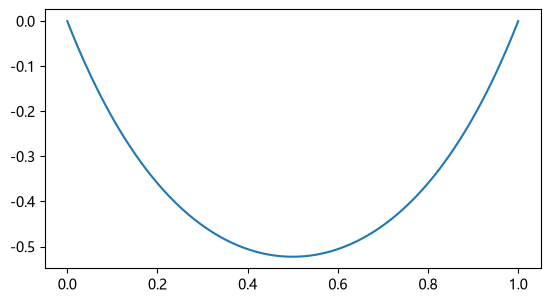

In [19]:
a = 0.3

tmp = []


def catenary_func(x, variables):
    """悬链线的微分方程，variables 是 (y, s)。"""
    tmp.append(variables.copy())
    y, s = variables
    dy = s / a
    ds = (1 + dy**2) ** 0.5
    return np.vstack((dy, ds))


def bc_func(vars_a, vars_b):
    """两端的 y 为 0 这一条件。"""
    ya, sa = vars_a
    yb, sb = vars_b
    return [ya - 0, yb - 0]


x = np.linspace(0, 1, 10)
variables = np.zeros((2, len(x)))
res = integrate.solve_bvp(catenary_func, bc_func, x, variables)

x2 = np.linspace(0, 1, 100)
y2, s2 = res.sol(x2)

fig, ax = plt.subplots()
ax.set_aspect("equal")
ax.plot(x2, y2)
plt.show()

## 小结

* 定积分用 `quad()` 计算，返回值是积分值与误差估计值。
* 二重积分用 `dblquad()`、三重积分用 `tplquad()`，其中 y 的区间以函数形式传入。
* 常微分方程用 `odeint()` 或 `solve_ivp()` 解，后者会自动选时刻，还能用 `dense_output` 做插值。
* 二阶微分方程先化成一阶联立方程再解。
* PID 控制的参数可以写一个评价响应的函数，再用 `optimize` 去搜索。
* 用弹簧连接的质点系统可以仿真悬链线，也能用 `solve_bvp()` 当作边界值问题来解。